### Dana Mounayer - s23108503

# CS4083 · Lab 2A — word2vec: Training Skip-gram and CBOW
**Chapter 3: Word Vectors I — word2vec** · Dr. Naila Marir · Effat University

### Goals
1. Check the softmax and the word2vec probability by hand with numpy.
2. Train **skip-gram** and **CBOW** word2vec models with gensim on the NLTK Brown corpus.
3. Compare nearest neighbours and solve **analogies** (*king − man + woman ≈ ?*), by hand and with gensim.
4. See how the **window size** and the **vector dimension** change the vectors.
5. Visualise the vectors in 2-D with PCA.
6. *Bonus:* implement skip-gram with negative sampling yourself in numpy.

**Time:** about 60–75 minutes. Cells marked `# TODO` are for you to complete.
The whole notebook runs in about 3 minutes on a laptop CPU.

## Part 0 — Setup

In [ ]:
# Uncomment if a package is missing:
!pip install nltk gensim scikit-learn matplotlib

import time, random
import numpy as np
import matplotlib.pyplot as plt
import nltk
from gensim.models import Word2Vec

nltk.download("brown", quiet=True)
from nltk.corpus import brown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 57.3 MB/s eta 0:00:00
Ready.


## Part 1 — Warm-up: the softmax by hand
In skip-gram, the probability of a context word $o$ given a centre word $c$ is

$$P(o \mid c) = \frac{\exp(u_o^\top v_c)}{\sum_{w \in V} \exp(u_w^\top v_c)}$$

### Task 1.1
Use the class activity numbers: $v_c = (2, 1)$ and three context vectors $u_a=(1,0)$, $u_b=(0,1)$, $u_c=(0,0)$
(one per row of `U`). Compute the scores, the softmax probabilities, and the loss $-\log P(b \mid c)$.

In [6]:
vc = np.array([2.0, 1.0])

U = np.array([
    [1.0, 0.0],  # a
    [0.0, 1.0],  # b
    [0.0, 0.0]   # c
])

def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

scores = U @ vc
probs = softmax(scores)

o = 1  # true context word is b
loss = -np.log(probs[o])

print("scores       :", scores)
print("probabilities:", probs.round(3), " sum =", probs.sum())
print("loss -log P(b|c) =", loss)

scores       : [2. 1. 0.]
probabilities: [0.665 0.245 0.09 ]  sum = 0.9999999999999999
loss -log P(b|c) = 1.4076059644443804


Check with your hand calculation from class: the probabilities should be about 0.665, 0.245 and 0.090.

### Task 1.2 — Observed minus expected
The gradient of $\log P(o \mid c)$ with respect to $v_c$ is $u_o - \sum_x P(x \mid c)\,u_x$.
Compute it for $o = b$, take one step $v_c \leftarrow v_c + 0.5 \times \text{gradient}$ and check that $P(b \mid c)$ goes **up**.

In [7]:
o = 1  # the true context word is b

expected = probs @ U
grad = U[o] - expected
v_new = vc + 0.5 * grad

print("expected:", expected.round(3), " gradient:", grad.round(3))
print(f"P(b|c): {probs[o]:.3f} -> {softmax(U @ v_new)[o]:.3f}")

expected: [0.665 0.245]  gradient: [-0.665  0.755]
P(b|c): 0.245 -> 0.386


## Part 2 — Prepare the corpus
The **Brown corpus** has about 1 million words of American English from 500 texts (news, fiction, science, ...).
gensim expects a list of sentences, each sentence a list of tokens.

### Task 2.1
Lowercase every word and keep only alphabetic tokens (`str.isalpha()`).

In [8]:
sentences = [
    [word.lower() for word in sentence if word.isalpha()]
    for sentence in brown.sents()
]

sentences = [s for s in sentences if len(s) > 1]

n_tokens = sum(len(s) for s in sentences)

print("Sentences:", len(sentences))
print("Tokens   :", n_tokens)
print("Example  :", sentences[1][:15])

Sentences: 55820
Tokens   : 980770
Example  : ['the', 'jury', 'further', 'said', 'in', 'presentments', 'that', 'the', 'city', 'executive', 'committee', 'which', 'had', 'charge', 'of']


## Part 3 — Train skip-gram and CBOW
Main parameters of `gensim.models.Word2Vec` (see the lecture slide *word2vec in practice*):

| parameter | meaning |
|---|---|
| `sg` | 1 = skip-gram, 0 = CBOW |
| `vector_size` | dimension $d$ of the vectors |
| `window` | window size $m$ |
| `min_count` | ignore words seen fewer times |
| `negative` | number of negative samples $K$ |
| `epochs` | passes over the corpus |

### Task 3.1
Train a **skip-gram** model and a **CBOW** model with `vector_size=100, window=5, min_count=5, negative=5, epochs=5, seed=SEED`.
Measure the training time of each.

*Note:* gensim trains with several threads, so your neighbours and numbers may differ slightly from your classmates' (and between runs).

In [9]:
params = dict(
    vector_size=100,
    window=5,
    min_count=5,
    negative=5,
    epochs=5,
    seed=SEED,
    workers=4
)

t0 = time.time()
sg_model = Word2Vec(sentences, sg=1, **params)
t_sg = time.time() - t0

t0 = time.time()
cbow_model = Word2Vec(sentences, sg=0, **params)
t_cbow = time.time() - t0

print(f"Vocabulary size: {len(sg_model.wv)} words")
print(f"Skip-gram training time: {t_sg:.1f} s")
print(f"CBOW training time     : {t_cbow:.1f} s")

Vocabulary size: 13344 words
Skip-gram training time: 26.4 s
CBOW training time     : 7.7 s


Each word now has a 100-dimensional vector. Remember from the lecture: gensim keeps the **centre** vectors $v_w$ in `model.wv`
(the context vectors $u_w$ are in `model.syn1neg`).

In [10]:
vec = sg_model.wv["monday"]
print("Shape:", vec.shape)
print("First 8 numbers:", vec[:8].round(3))

Shape: (100,)
First 8 numbers: [ 0.006 -0.014  0.132  0.044 -0.208  0.232 -0.051 -0.19 ]


## Part 4 — Nearest neighbours
`model.wv.most_similar(word, topn=k)` returns the $k$ words with the highest **cosine similarity**.

### Task 4.1
Write a function that prints the 6 nearest neighbours of a word for **both** models side by side.
Try it on the words below and add two words of your own.

In [11]:
def compare_neighbours(word, topn=6):
    sg_nn = [w for w, s in sg_model.wv.most_similar(word, topn=topn)]
    cb_nn = [w for w, s in cbow_model.wv.most_similar(word, topn=topn)]

    print(f"{word:>11} | skip-gram: {', '.join(sg_nn)}")
    print(f"{'':>11} | CBOW     : {', '.join(cb_nn)}")

for w in ["monday", "money", "good", "university", "water", "she", "car", "wife"]:
    compare_neighbours(w)

     monday | skip-gram: tuesday, thursday, saturday, friday, wednesday, sunday
            | CBOW     : wednesday, sunday, tuesday, april, crossing, gate
      money | skip-gram: job, benefits, sue, unable, excuse, permission
            | CBOW     : trouble, work, job, care, educator, chance
       good | skip-gram: nice, bad, lonely, sad, fine, fun
            | CBOW     : bad, real, indeed, quite, word, perhaps
 university | skip-gram: college, harvard, chicago, graduate, california, brooklyn
            | CBOW     : club, meeting, century, center, conference, june
      water | skip-gram: dust, dry, wash, edges, air, ground
            | CBOW     : ground, table, bottom, air, top, surface
        she | skip-gram: herself, henrietta, mama, her, he, lucy
            | CBOW     : he, i, him, me, boy, miss
        car | skip-gram: kitchen, truck, ball, garden, phone, box
            | CBOW     : bed, room, road, house, kitchen, window
       wife | skip-gram: father, mother, brother, 

**Think:** which model gives more sensible neighbours on this small corpus? Is this what the lecture said about
skip-gram and CBOW? Do you see neighbours that are *related* but not *similar* (e.g. antonyms like *good* / *bad*)?

Skip-gram gives more sensible neighbours overall on this small corpus. For example, it finds related words such as *university–college*, *car–truck*, and *wife–mother*. CBOW is faster to train (7.7 seconds compared with 26.4 seconds for Skip-gram), which agrees with the lecture. Skip-gram often performs better on less frequent words, while CBOW is generally faster and works well for frequent words. Some neighbours are related but not similar in meaning, such as *good–bad*, because they can appear in similar contexts.


### Task 4.2 — A tiny similarity test
For each triple (word, related, unrelated), a good model should give `cos(word, related) > cos(word, unrelated)`.
Compute (a) the **accuracy**: the fraction of triples where this is true, and (b) the **mean gap**
`cos(word, related) - cos(word, unrelated)` averaged over the triples (larger = clearer separation).

In [12]:
TRIPLES = [("monday", "friday", "water"), ("car", "truck", "music"), ("man", "woman", "table"),
           ("water", "river", "money"), ("house", "room", "president"), ("king", "queen", "river"),
           ("red", "blue", "government"), ("father", "mother", "church"), ("city", "town", "color"),
           ("war", "army", "bread"), ("doctor", "hospital", "football"), ("eat", "food", "election")]

def triple_score(wv, triples=TRIPLES):
    gaps = np.array([
        wv.similarity(w, r) - wv.similarity(w, u)
        for w, r, u in triples
        if w in wv.key_to_index
        and r in wv.key_to_index
        and u in wv.key_to_index
    ])

    accuracy = np.mean(gaps > 0)
    mean_gap = np.mean(gaps)

    return round(float(accuracy), 3), round(float(mean_gap), 3)

print("skip-gram (accuracy, mean gap):", triple_score(sg_model.wv))
print("CBOW      (accuracy, mean gap):", triple_score(cbow_model.wv))

skip-gram (accuracy, mean gap): (1.0, 0.388)
CBOW      (accuracy, mean gap): (0.917, 0.223)


Skip-gram performs better than CBOW on this similarity test. It correctly ranks the related word above the unrelated word in all 12 triples, achieving 100% accuracy and a mean gap of 0.388. CBOW achieves 91.7% accuracy and a mean gap of 0.223. This suggests that Skip-gram separates related and unrelated words more clearly on these examples.


## Part 5 — Analogies
To solve *a : b :: c : ?* (e.g. *man : king :: woman : ?*) we look for the word $x$ closest to
$v_b - v_a + v_c$, using **normalised** vectors and cosine similarity, and we exclude the three input words.

### Task 5.1
Implement `analogy(wv, a, b, c)` with numpy. Use `wv.get_normed_vectors()` (one unit-length row per word) and `wv.index_to_key`.
Then compare with gensim's `most_similar(positive=[b, c], negative=[a])`.

In [14]:

def analogy(wv, a, b, c, topn=3):
    E = wv.get_normed_vectors()

    # Calculate target vector: b - a + c
    target = (
        E[wv.key_to_index[b]]
        - E[wv.key_to_index[a]]
        + E[wv.key_to_index[c]]
    )

    # Normalize target
    target = target / np.linalg.norm(target)

    # Cosine similarities with all words
    sims = E @ target

    best = []
    for idx_word in np.argsort(-sims):
        word = wv.index_to_key[idx_word]

        if word in (a, b, c):
            continue

        best.append((word, round(float(sims[idx_word]), 3)))

        if len(best) == topn:
            break

    return best


print("ours:", analogy(sg_model.wv, "man", "king", "woman"))

print("gensim:", [
    (w, round(s, 3))
    for w, s in sg_model.wv.most_similar(
        positive=["king", "woman"],
        negative=["man"],
        topn=3
    )
])

ours: [('mary', 0.833), ('ann', 0.82), ('anne', 0.819)]
gensim: [('mary', 0.833), ('ann', 0.82), ('anne', 0.819)]


### Task 5.2 — Brown vs. a big pre-trained model
One million words is small for word2vec. Load the pre-trained 50-d GloVe vectors (6 billion tokens of Wikipedia + news,
Chapter 4) and solve the same analogies with both. Add two analogies of your own.

In [15]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-50")

ANALOGIES = [("man", "king", "woman"), ("france", "paris", "germany"), ("he", "his", "she"),
             ("good", "better", "bad"), ("walked", "walking", "swam"), ("saudi", "riyadh", "egypt")]
for a, b, c in ANALOGIES:
    brown_ans = analogy(sg_model.wv, a, b, c, 1)[0][0] if all(w in sg_model.wv for w in (a, b, c)) else "(OOV)"
    glove_ans = analogy(glove, a, b, c, 1)[0][0]
    print(f"{a}:{b} :: {c}:?   Brown skip-gram -> {brown_ans:<10} GloVe -> {glove_ans}")

man:king :: woman:?   Brown skip-gram -> mary       GloVe -> queen
france:paris :: germany:?   Brown skip-gram -> georgia    GloVe -> berlin
he:his :: she:?   Brown skip-gram -> her        GloVe -> her
good:better :: bad:?   Brown skip-gram -> worse      GloVe -> worse
walked:walking :: swam:?   Brown skip-gram -> buffet     GloVe -> swim
saudi:riyadh :: egypt:?   Brown skip-gram -> (OOV)      GloVe -> cairo


**Think:** which analogies work with Brown, which only with GloVe? Why does the corpus size matter so much?
What does `(OOV)` mean?

GloVe correctly solved man:king :: woman:queen and france:paris :: germany:berlin, while Brown predicted Mary and Georgia, respectively. Both models correctly predicted her for he:his :: she:?, and worse for good:better :: bad:?. For walked:walking :: swam:?, GloVe predicted swim, while Brown predicted buffet; for saudi:riyadh :: egypt:?, GloVe predicted Cairo, while Saudi was out of vocabulary in Brown.

GloVe learns better relationships from its much larger training corpus, and OOV means “out of vocabulary,” meaning a word is missing from the model's vocabulary.


## Part 6 — Window size and dimension
### Task 6.1 — Window size
Train two skip-gram models with `window=2` and `window=10` (keep the other parameters).
Compare the neighbours of a few words. Small windows tend to give **syntactic** neighbours (same type of word),
large windows **topical** neighbours (same subject).

In [16]:
t0 = time.time()

w2 = Word2Vec(
    sentences,
    sg=1,
    **{**params, "window": 2}
)

w10 = Word2Vec(
    sentences,
    sg=1,
    **{**params, "window": 10}
)

print(f"trained in {time.time() - t0:.1f} s")

for w in ["walked", "red", "church", "music"]:
    print(f"{w:>8} | window 2 : {', '.join(x for x, _ in w2.wv.most_similar(w, topn=6))}")
    print(f"{'':>8} | window 10: {', '.join(x for x, _ in w10.wv.most_similar(w, topn=6))}")
print("triple score  window 2:", triple_score(w2.wv), "| window 10:", triple_score(w10.wv))

trained in 41.9 s
  walked | window 2 : moved, ran, swung, climbed, drove, sat
         | window 10: climbed, stepped, swung, drove, hurried, waited
     red | window 2 : black, pink, gray, yellow, blue, stone
         | window 10: sand, orange, marching, huge, pine, thunder
  church | window 2 : meeting, news, spirits, party, neighborhood, steady
         | window 10: congregation, fellowship, prayer, catholic, worship, belongs
   music | window 2 : bible, humor, medium, skill, imagination, memory
         | window 10: musical, jazz, dance, style, writing, book
triple score  window 2: (1.0, 0.271) | window 10: (1.0, 0.413)


### Task 6.2 — Dimension
Train a skip-gram model with only `vector_size=10` and compare its neighbours with the 100-d model.

In [17]:
d10 = Word2Vec(
    sentences,
    sg=1,
    **{**params, "vector_size": 10}
)

for w in ["monday", "university", "music"]:
    print(f"{w:>10} | d=10 :",
          ', '.join(x for x, _ in d10.wv.most_similar(w, topn=6)))
    print(f"{'':>10} | d=100:",
          ', '.join(x for x, _ in sg_model.wv.most_similar(w, topn=6)))

    monday | d=10 : friday, tuesday, hospital, post, office, sunday
           | d=100: tuesday, thursday, saturday, friday, wednesday, sunday
university | d=10 : junior, california, island, chicago, rhode, meeting
           | d=100: college, harvard, chicago, graduate, california, brooklyn
     music | d=10 : marvelous, silly, classical, partisan, tale, overnight
           | d=100: musical, english, romantic, style, heroic, medieval


**Think:** what is lost when the dimension is too small? Why would a very large dimension (e.g. 1000) not help on Brown?

With vector_size=10, the model had less capacity to represent word relationships, producing less sensible neighbours for words such as university than the 100-dimensional model.

For example, the 100-dimensional model returned college for university, while the 10-dimensional model returned junior. A dimension of 1,000 would require more data and computation and could overfit the small Brown corpus without improving the learned relationships.


## Part 7 — A 2-D picture with PCA
### Task 7.1
Project the skip-gram vectors of the words below to 2-D with `sklearn.decomposition.PCA` and plot them with labels.
Do the groups separate?

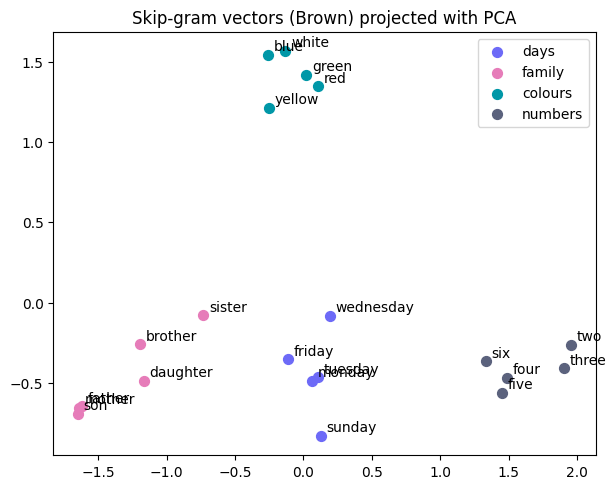

In [18]:

from sklearn.decomposition import PCA

groups = {
    "days": ["monday", "tuesday", "wednesday", "friday", "sunday"],
    "family": ["father", "mother", "brother", "sister", "son", "daughter"],
    "colours": ["red", "blue", "green", "yellow", "white"],
    "numbers": ["two", "three", "four", "five", "six"],
}

words = [w for g in groups.values() for w in g]

X = np.array([sg_model.wv[w] for w in words])
Y = PCA(n_components=2, random_state=SEED).fit_transform(X)

colours = ["#6D6AF7", "#E67CB9", "#0097A7", "#5B627D"]

plt.figure(figsize=(7, 5.5))
k = 0

for (name, ws), col in zip(groups.items(), colours):
    plt.scatter(
        Y[k:k + len(ws), 0],
        Y[k:k + len(ws), 1],
        color=col,
        label=name,
        s=50
    )

    for i, w in enumerate(ws):
        plt.annotate(
            w, Y[k + i],
            xytext=(4, 3),
            textcoords="offset points"
        )

    k += len(ws)

plt.legend()
plt.title("Skip-gram vectors (Brown) projected with PCA")
plt.show()

**Think:** PCA keeps only 2 of 100 dimensions. What could go wrong when we judge vectors from a 2-D plot?

PCA reduces the original 100-dimensional vectors to only two dimensions, so some information about word relationships is lost. Words that are similar in the original space may appear far apart in the plot, and apparent closeness in two dimensions does not necessarily mean that the words are highly similar in the original space.


## Part 8 (Bonus) — Skip-gram with negative sampling in numpy
Now build word2vec yourself on a tiny corpus. For one (centre $c$, context $o$) pair and $K$ negative words $k$:

$$J = -\log \sigma(u_o^\top v_c) - \sum_{k=1}^{K} \log \sigma(-u_k^\top v_c)$$

Gradients (derive them yourself as an exercise, using $\sigma'(x) = \sigma(x)(1-\sigma(x))$):
- $\partial J / \partial v_c = -(1 - \sigma(u_o^\top v_c))\,u_o + \sum_k \sigma(u_k^\top v_c)\,u_k$
- $\partial J / \partial u_o = -(1 - \sigma(u_o^\top v_c))\,v_c$
- $\partial J / \partial u_k = \sigma(u_k^\top v_c)\,v_c$

Negative words are sampled from the unigram distribution raised to the power 3/4.

In [19]:
tiny = ["i drink hot tea every morning", "i drink hot coffee every morning",
        "she drinks tea with milk", "he drinks coffee with milk",
        "the cat sat on the mat", "the dog sat on the mat",
        "the cat chased the mouse", "the dog chased the cat"] * 30
toks = [s.split() for s in tiny]
vocab = sorted({w for s in toks for w in s})
idx = {w: i for i, w in enumerate(vocab)}
counts = np.zeros(len(vocab))
for s in toks:
    for w in s:
        counts[idx[w]] += 1
noise = counts ** 0.75
noise /= noise.sum()
print(len(vocab), "words; noise distribution sums to", noise.sum().round(3))

20 words; noise distribution sums to 1.0


In [21]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

rng = np.random.default_rng(SEED)
d, m, K, lr = 10, 2, 3, 0.05
Vc = rng.normal(0, 0.1, (len(vocab), d))    # centre vectors v_w
Uo = rng.normal(0, 0.1, (len(vocab), d))    # context vectors u_w


for epoch in range(20):
    total = 0.0

    for s in toks:
        ids = [idx[w] for w in s]

        for t, c in enumerate(ids):
            for j in range(max(0, t - m), min(len(ids), t + m + 1)):
                if j == t:
                    continue

                o = ids[j]
                negs = rng.choice(len(vocab), size=K, p=noise)

                v = Vc[c].copy()

                # Probability of the true context word
                s_o = sigmoid(Uo[o] @ v)

                # Probabilities of the negative samples
                s_k = sigmoid(Uo[negs] @ v)

                total += -np.log(s_o + 1e-10) - np.log(1 - s_k + 1e-10).sum()

                # Gradient with respect to the centre vector
                grad_v = (
                    -(1 - s_o) * Uo[o]
                    + np.sum(s_k[:, None] * Uo[negs], axis=0)
                )

                # Update the positive context vector
                Uo[o] -= lr * (-(1 - s_o) * v)

                # Update the negative context vectors
                np.subtract.at(Uo, negs, lr * np.outer(s_k, v))

                # Update the centre vector
                Vc[c] -= lr * grad_v

    if epoch % 5 == 0 or epoch == 19:
        print(f"epoch {epoch:2d}  loss {total:.1f}")

epoch  0  loss 7701.1
epoch  5  loss 5036.2
epoch 10  loss 5061.9
epoch 15  loss 5053.1
epoch 19  loss 5034.6


In [22]:
def cos(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

for a, b in [("tea", "coffee"), ("cat", "dog"), ("tea", "cat"), ("coffee", "mat")]:
    print(f"cos({a}, {b}) = {cos(Vc[idx[a]], Vc[idx[b]]):+.2f}")

cos(tea, coffee) = +0.75
cos(cat, dog) = +0.98
cos(tea, cat) = +0.09
cos(coffee, mat) = +0.22


**Think:** *tea* and *coffee* never appear in the same sentence. Why do they still get similar vectors?

Tea and coffee can develop similar vectors because they appear in similar contexts, such as drink, hot, and every morning. Their cosine similarity of 0.75 in my implementation indicates that the model learned this relationship even though the words never occur in the same sentence.


## Part 9 — Reflection (submit with your notebook)
Answer in 2–3 sentences each:
1. Which model (skip-gram or CBOW) gave better neighbours on Brown, and which was faster? Use your numbers.

Skip-gram gave better neighbours overall, achieving 100% accuracy and a mean gap of 0.388, compared with CBOW's 91.7% accuracy and 0.223 mean gap. However, CBOW was faster, taking 7.7 seconds compared with 26.4 seconds for Skip-gram.


2. Explain in your own words why the gradient of $\log P(o \mid c)$ is "observed minus expected" (Part 1.2).

The observed part is the vector of the correct context word, while the expected part is the probability-weighted average of all possible context vectors. Subtracting the expected vector from the observed vector adjusts the centre vector toward the correct context word and away from the model's current prediction.

3. Give one analogy that worked with GloVe but not with the Brown model. Why the difference?

For man:king :: woman:?, GloVe correctly predicted queen, while Brown predicted Mary. GloVe was trained on a much larger corpus, allowing it to learn richer semantic relationships than the smaller Brown corpus.

4. How did the window size change the neighbours? Give one example.

A small window focused on nearby words, while a large window captured broader topical relationships. For church, window 10 returned congregation, fellowship, prayer, Catholic, and worship, while window 2 returned meeting, news, spirits, party, and neighborhood.

5. What happened with `vector_size=10`? Why?

The 10-dimensional model produced less meaningful neighbours for some words than the 100-dimensional model because it had less capacity to represent word relationships. For example, the 100-dimensional model returned college for university, while the 10-dimensional model returned junior.

6. *(Bonus)* In your numpy implementation, what is the role of the negative samples? What would happen with $K = 0$?

Negative samples teach the model to distinguish real context words from randomly sampled words, helping it learn useful word vectors. If K=0, there are no negative examples, so the model loses the contrastive learning signal that helps distinguish true context words from other words.
